# Vanilla RNN

| Symbol | Meaning | Shape |
|---|---|---|
| \(x_t\) | One-hot encoding of the current character | `[B, V]` |
| \(h_{t-1}\) | Previous hidden state | `[B, H]` |
| \(W_{xh}\) | Input-to-hidden weights | `[V, H]` |
| \(W_{hh}\) | Hidden-to-hidden weights | `[H, H]` |
| \(h_t\) | Updated hidden state | `[B, H]` |
| \(W_{hy}\) | Hidden-to-output weights | `[H, V]` |
| \(z_t\) | Next-character logits | `[B, V]` |

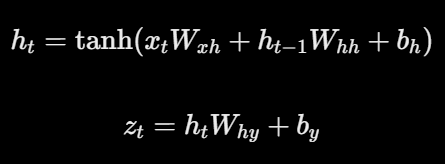

Same weights across the layers, only input and hidden state change

In [85]:
import torch
import torch.nn.functional as F
from torch import nn

import math
import random
import os
import time
from datetime import datetime

import numpy as np
import h5py
import matplotlib.pyplot as plt
from matplotlib.pyplot import imread
import scipy
from PIL import Image
import pandas as pd

from typing import Sequence

In [86]:
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

text = "i love learning! " * 1000
text_all = "the quick brown fox jumps over the lazy dog." * 1000

In [87]:
# Vocabulary and character-to-integer mappings.
chars = sorted(set(text))
vocab_size = len(chars)

stoi = {char: index for index, char in enumerate(chars)}
itos = {index: char for char, index in stoi.items()}

In [ ]:
def encode(text):
    ''' return [indexes] from string'''
    return [stoi[char] for char in text]

def decode(ids):
    ''' return string from [indexes]'''
    return "".join(itos[int(index)] for index in ids)

data = torch.tensor(encode(text), dtype=torch.long)

print("Vocabulary:", chars)
print("Vocabulary size:", vocab_size)
print("Encoded example:", encode("learner")) 
print("Decoded example:", decode([3,2,9,5,7,4])) #754439

Vocabulary: [' ', '!', 'a', 'e', 'g', 'i', 'l', 'n', 'o', 'r', 'v']
Vocabulary size: 11
Encoded example: [6, 3, 2, 9, 7, 3, 9]
Decoded example: earing


In [100]:
def get_batch(data, batch_size=32, seq_len=32):
    ''' get batch of batch_size (sequences) with sequence length = seq_len.'''
    if len(data) <= seq_len:
        raise ValueError("Data must contain more than seq_len characters.")

    # Each sample needs seq_len inputs plus one final target.
    # Randomly chose a starting point to start a batch 
    starts = torch.randint(low=0, high=len(data) - seq_len, size=(batch_size,), )

    x = torch.stack([data[start : start + seq_len] for start in starts.tolist()])

    y = torch.stack([data[start + 1 : start + seq_len + 1] for start in starts.tolist()])

    return x.to(device), y.to(device)


x, y = get_batch(data, batch_size=6, seq_len=10)

print("Shapes:", x.shape, y.shape)
print()

for i, j in zip(x, y):
    print(f"Input = {decode(i.tolist())} - Target = {decode(j.tolist())}")

Shapes: torch.Size([6, 10]) torch.Size([6, 10])

Input =  love lear - Target = love learn
Input = rning! i l - Target = ning! i lo
Input =  i love le - Target = i love lea
Input = earning! i - Target = arning! i 
Input = ove learni - Target = ve learnin
Input =  i love le - Target = i love lea


In [ ]:
class VanillaRNN(nn.Module):
    def __init__(self, vocab_size, hidden_size):
        super(VanillaRNN, self).__init__()
        self.vocab_size = vocab_size
        self.hidden_size = hidden_size

        # Trainable pars
        self.W_xh = nn.Parameter(torch.empty(vocab_size, hidden_size)) # weight for input to hidden
        self.W_hh = nn.Parameter(torch.empty(hidden_size, hidden_size)) # weight for hidden to hidden
        self.W_hy = 
        